In [14]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/Wayne-on-the-road/ResHybnet/main/"

edges = pd.read_csv(BASE + "sample_data/1-data-test-undirected_edge.csv")
nodes = pd.read_csv(BASE + "sample_data/1-data-test-combine.csv")

nodes["node_id"] = nodes.index   # row number hi graph ka node ID hai

print("edges:", edges.shape)
print("nodes:", nodes.shape)
display(edges.head(3))
display(nodes[["node_id", "user_index", "date", "label"]].head(3))

edges: (207576, 2)
nodes: (1908, 11)


,start,end
0,0,79
1,0,1463
2,0,4


,node_id,user_index,date,label
0,0,BNR0965,2010-01-04 00:00:00,0
1,1,COM0321,2010-01-04 00:00:00,0
2,2,ETR0428,2010-01-04 00:00:00,0


In [15]:
import networkx as nx

G = nx.Graph()                                              # undirected graph
G.add_nodes_from(nodes["node_id"])                          # 1908 nodes
G.add_edges_from(edges.itertuples(index=False, name=None))  # har row ko (start, end) pair banake add karo

print("nodes:", G.number_of_nodes())
print("edges:", G.number_of_edges())
print("directed?", G.is_directed())

nodes: 1908
edges: 53056
directed? False


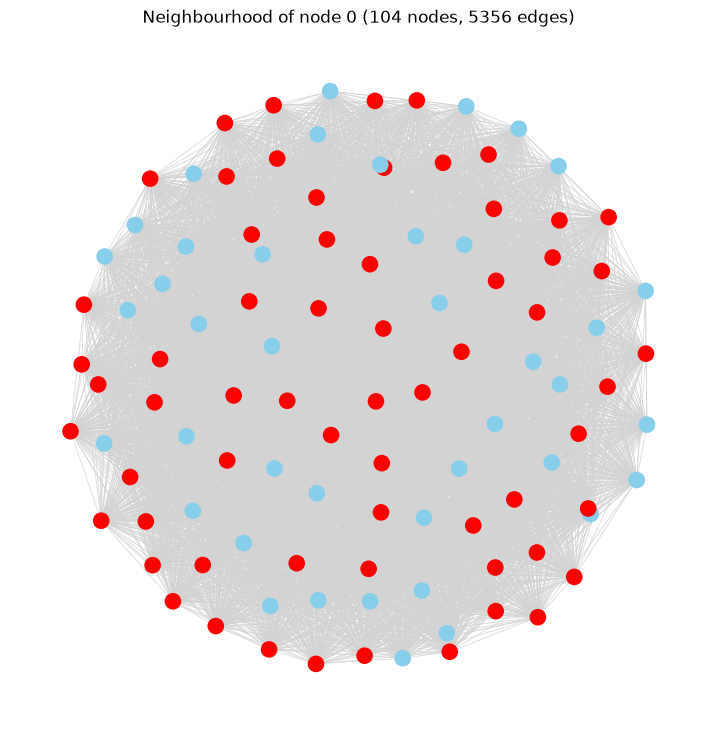

In [16]:
import matplotlib.pyplot as plt

sub = nx.ego_graph(G, 0)    # node 0 aur uske saare direct neighbors
colors = ["red" if nodes.loc[n, "label"] == 1 else "skyblue" for n in sub.nodes]

plt.figure(figsize=(9, 9))
pos = nx.spring_layout(sub, seed=42)
nx.draw_networkx(sub, pos, node_color=colors, node_size=120,
                 with_labels=False, edge_color="lightgray", width=0.5)
plt.title(f"Neighbourhood of node 0 ({sub.number_of_nodes()} nodes, {sub.number_of_edges()} edges)")
plt.axis("off")
plt.show()

In [17]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/Wayne-on-the-road/ResHybnet/main/"

users = pd.read_csv(
    BASE + "code_for_sequence_process/cert4.2_data/userlist.csv"
)

print("Userlist shape:", users.shape)
print("Columns:", users.columns.tolist())

display(users.head())

Userlist shape: (1000, 9)
Columns: ['employee_name', 'user_id', 'email', 'role', 'business_unit', 'functional_unit', 'department', 'team', 'supervisor']


,employee_name,user_id,email,role,business_unit,functional_unit,department,team,supervisor
0,Calvin Edan Love,CEL0561,Calvin.Edan.Love@dtaa.com,ComputerProgrammer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
1,Christine Reagan Deleon,CRD0624,Christine.Reagan.Deleon@dtaa.com,Salesman,1,5 - SalesAndMarketing,2 - Sales,3 - RegionalSales,Winter Veda Burks
2,Jade Felicia Caldwell,JFC0557,Jade.Felicia.Caldwell@dtaa.com,SoftwareEngineer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
3,Aquila Stewart Dejesus,ASD0577,Aquila.Stewart.Dejesus@dtaa.com,ProductionLineWorker,1,3 - Manufacturing,3 - Assembly,3 - AssemblyDept,Whilemina Pandora England
4,Micah Abdul Rojas,MAR0955,Micah.Abdul.Rojas@dtaa.com,ProductionLineWorker,1,3 - Manufacturing,3 - Assembly,6 - AssemblyDept,Sandra Beverly Diaz


In [18]:
print("Missing user IDs:", users["user_id"].isna().sum())
print("Duplicate user IDs:", users["user_id"].duplicated().sum())

print("Missing supervisors:", users["supervisor"].isna().sum())

supervisor_names = set(users["supervisor"].dropna())
employee_names = set(users["employee_name"])

unmatched = supervisor_names - employee_names

print("Unique supervisors:", len(supervisor_names))
print("Unmatched supervisors:", len(unmatched))
print("Unmatched names:", unmatched)

Missing user IDs: 0
Duplicate user IDs: 0
Missing supervisors: 1
Unique supervisors: 67
Unmatched supervisors: 0
Unmatched names: set()


In [19]:
print("Sample columns:", nodes.columns.tolist())

print("Unique user_index:", nodes["user_index"].nunique())
print("Unique user_id:", users["user_id"].nunique())

print("Sample users missing in userlist:",
      len(set(nodes["user_index"]) - set(users["user_id"])))

print("Userlist employees missing in sample:",
      len(set(users["user_id"]) - set(nodes["user_index"])))

Sample columns: ['index', 'date_index', 'user_index', 'date', 'label', 'f1', 'f2', 'f3', 'f4', 'f5', 'node_id']
Unique user_index: 649
Unique user_id: 1000
Sample users missing in userlist: 0
Userlist employees missing in sample: 351


In [20]:
missing_supervisor = users[users["supervisor"].isna()]

display(
    missing_supervisor[
        ["employee_name", "user_id", "department", "supervisor"]
    ]
)

,employee_name,user_id,department,supervisor
809,Mona Susan Shannon,MSS0001,NaN,NaN


In [21]:
mona_samples = nodes[nodes["user_index"] == "MSS0001"]

print("Mona's User-Day Samples:", len(mona_samples))
display(mona_samples[["node_id", "user_index", "date", "label"]])

Mona's User-Day Samples: 1


,node_id,user_index,date,label
1453,1453,MSS0001,2011-01-17 00:00:00,0


In [22]:
sample_users = nodes["user_index"].unique()

sample_userlist = users[users["user_id"].isin(sample_users)].copy()

print("Employees in sample:", len(sample_users))
print("Employees mapped:", len(sample_userlist))
print("Employees with missing supervisor:",
      sample_userlist["supervisor"].isna().sum())

display(
    sample_userlist[
        ["employee_name", "user_id", "supervisor"]
    ].head(10)
)

Employees in sample: 649
Employees mapped: 649
Employees with missing supervisor: 1


,employee_name,user_id,supervisor
0,Calvin Edan Love,CEL0561,Stephanie Briar Harrington
2,Jade Felicia Caldwell,JFC0557,Stephanie Briar Harrington
3,Aquila Stewart Dejesus,ASD0577,Whilemina Pandora England
4,Micah Abdul Rojas,MAR0955,Sandra Beverly Diaz
5,Gail Rhiannon Mcconnell,GRM0868,Hashim Damon Dudley
9,Aurora Sarah Manning,ASM0575,Whilemina Pandora England
11,Jacqueline Latifah Miles,JLM0364,Francis Brian Armstrong
13,Grant Camden Gay,GCG0951,Sandra Beverly Diaz
15,Aspen Amber Vinson,AAV0450,Armando Albert Walter
16,Colorado John Valentine,CJV0286,Rose Hanae Yates


In [23]:
name_to_id = dict(
    zip(users["employee_name"], users["user_id"])
)

sample_userlist["supervisor_id"] = (
    sample_userlist["supervisor"].map(name_to_id)
)

print("Missing supervisor IDs:",
      sample_userlist["supervisor_id"].isna().sum())

display(
    sample_userlist[
        ["employee_name", "user_id", "supervisor",
         "supervisor_id"]
    ].head(10)
)

Missing supervisor IDs: 1


,employee_name,user_id,supervisor,supervisor_id
0,Calvin Edan Love,CEL0561,Stephanie Briar Harrington,SBH0537
2,Jade Felicia Caldwell,JFC0557,Stephanie Briar Harrington,SBH0537
3,Aquila Stewart Dejesus,ASD0577,Whilemina Pandora England,WPE0538
4,Micah Abdul Rojas,MAR0955,Sandra Beverly Diaz,SBD0913
5,Gail Rhiannon Mcconnell,GRM0868,Hashim Damon Dudley,HDD0789
9,Aurora Sarah Manning,ASM0575,Whilemina Pandora England,WPE0538
11,Jacqueline Latifah Miles,JLM0364,Francis Brian Armstrong,FBA0348
13,Grant Camden Gay,GCG0951,Sandra Beverly Diaz,SBD0913
15,Aspen Amber Vinson,AAV0450,Armando Albert Walter,AAW0353
16,Colorado John Valentine,CJV0286,Rose Hanae Yates,RHY0079


In [24]:
user_day_nodes = (
    nodes.groupby("user_index")["node_id"]
    .apply(list)
    .to_dict()
)

print("Total employees:", len(user_day_nodes))
print("Example employee:", list(user_day_nodes.items())[:3])

print("Mona's nodes:", user_day_nodes.get("MSS0001"))

Total employees: 649
Example employee: [('AAE0190', [269, 767]), ('AAF0535', [37, 188, 270, 344, 351, 356, 360, 369, 379, 387, 397, 409, 419, 428, 443, 455, 471, 484, 495, 505, 516, 528, 540, 606, 627, 649, 660, 680, 692, 738]), ('AAM0658', [1111])]
Mona's nodes: [1453]


In [25]:
supervisor_mapping = sample_userlist[
    ["user_id", "supervisor_id"]
].dropna()

for _, row in supervisor_mapping.head(5).iterrows():
    employee = row["user_id"]
    supervisor = row["supervisor_id"]

    print(
        employee, "->", supervisor,
        "| Employee nodes:", user_day_nodes.get(employee, []),
        "| Supervisor nodes:", user_day_nodes.get(supervisor, [])
    )

CEL0561 -> SBH0537 | Employee nodes: [1300, 1566, 1902] | Supervisor nodes: [259, 1904]
JFC0557 -> SBH0537 | Employee nodes: [431, 1275] | Supervisor nodes: [259, 1904]
ASD0577 -> WPE0538 | Employee nodes: [561] | Supervisor nodes: [1876]
MAR0955 -> SBD0913 | Employee nodes: [1562, 1570, 1586, 1736] | Supervisor nodes: [4, 1811, 1838]
GRM0868 -> HDD0789 | Employee nodes: [257] | Supervisor nodes: []


In [26]:
supervisor_ids = set(
    sample_userlist["supervisor_id"].dropna()
)

supervisors_in_samples = {
    sid for sid in supervisor_ids
    if sid in user_day_nodes
}

print("Unique supervisors:", len(supervisor_ids))
print("Supervisors with samples:", len(supervisors_in_samples))
print("Supervisors without samples:",
      len(supervisor_ids - supervisors_in_samples))

print("Missing from sample:", sorted(supervisor_ids - supervisors_in_samples))

Unique supervisors: 67
Supervisors with samples: 46
Supervisors without samples: 21
Missing from sample: ['AAW0353', 'ATP0662', 'BTW0005', 'CMB0912', 'CNE0352', 'DCC0160', 'DTT0076', 'GKO0078', 'GNS0178', 'GTD0116', 'HDD0789', 'HTH0007', 'KBP0008', 'LAM0911', 'MAW0166', 'RHY0079', 'SGG0787', 'TVS0006', 'WBC0192', 'WKF0012', 'WVB0539']


In [27]:
common_supervisor_groups = (
    sample_userlist.dropna(subset=["supervisor_id"])
    .groupby("supervisor_id")["user_id"]
    .apply(list)
)

shared_groups = common_supervisor_groups[
    common_supervisor_groups.apply(lambda x: len(x) > 1)
]

print("Total shared-supervisor groups:", len(shared_groups))

print("Employee pairs sharing supervisors:",
      sum(len(group) * (len(group) - 1) // 2
          for group in shared_groups))

display(shared_groups.head(10))

Total shared-supervisor groups: 65
Employee pairs sharing supervisors: 4267


supervisor_id
AAE0190                 [SAT0194, CSP0197, YIC0195, TOR0193]
AAW0353    [AAV0450, GHL0460, KPP0452, MLG0475, ERH0449, ...
ABH0663    [JJB0700, YJV0699, MBR0724, AKF0709, RLB0719, ...
ALC0788    [FRR0832, AHD0848, AES0827, MNR0829, MSG0839, ...
AMD0077                                   [HCM0267, LDB0090]
AMM0014                 [LNS0989, DLH0029, KVT0028, DIC0988]
ATP0662    [NGO0690, CCH0685, CAM0681, IAR0694, QJR0688, ...
BHC0665    [TYB0779, CMW0783, IJM0776, CFM0767, UAD0771, ...
BJH0354    [LQC0479, CJC0494, NAH0503, HCV0478, CKB0482, ...
BRB0355    [FMG0527, BDI0533, BMT0528, HLH0512, GCS0518, ...
Name: user_id, dtype: object

In [28]:
# Employees having more than one User-Day Sample
multiple_day_users = {
    user: sample_nodes
    for user, sample_nodes in user_day_nodes.items()
    if len(sample_nodes) > 1
}

print("Employees with multiple samples:", len(multiple_day_users))

print("Total possible same-user connections:",
      sum(
          len(sample_nodes) * (len(sample_nodes) - 1) // 2
          for sample_nodes in multiple_day_users.values()
      ))

display(list(multiple_day_users.items())[:5])

Employees with multiple samples: 310
Total possible same-user connections: 12853


[('AAE0190', [269, 767]),
 ('AAF0535',
  [37,
   188,
   270,
   344,
   351,
   356,
   360,
   369,
   379,
   387,
   397,
   409,
   419,
   428,
   443,
   455,
   471,
   484,
   495,
   505,
   516,
   528,
   540,
   606,
   627,
   649,
   660,
   680,
   692,
   738]),
 ('ABC0174',
  [1096,
   1102,
   1112,
   1121,
   1131,
   1138,
   1144,
   1151,
   1157,
   1162,
   1166,
   1175,
   1181,
   1188,
   1193,
   1203,
   1207,
   1215,
   1225,
   1236,
   1244,
   1250,
   1272,
   1290,
   1309,
   1317,
   1336,
   1345,
   1357]),
 ('ABC0253', [129, 245]),
 ('ABH0663', [161, 380, 1455, 1506])]

In [29]:
from itertools import combinations

same_user_edges = set()

for sample_nodes in user_day_nodes.values():
    for u, v in combinations(sample_nodes, 2):
        same_user_edges.add(tuple(sorted((u, v))))

print("Rule 3 - Same User Edges:", len(same_user_edges))
print("First 10 edges:", list(same_user_edges)[:10])

Rule 3 - Same User Edges: 12853
First 10 edges: [(1558, 1803), (612, 676), (1596, 1829), (491, 615), (1623, 1703), (1428, 1464), (707, 913), (1834, 1886), (633, 735), (677, 778)]


In [30]:
from itertools import product

supervisor_edges = set()

for _, row in sample_userlist.dropna(subset=["supervisor_id"]).iterrows():

    employee_id = row["user_id"]
    supervisor_id = row["supervisor_id"]

    employee_nodes = user_day_nodes.get(employee_id, [])
    supervisor_nodes = user_day_nodes.get(supervisor_id, [])

    for u, v in product(employee_nodes, supervisor_nodes):
        if u != v:
            supervisor_edges.add(tuple(sorted((u, v))))

print("Rule 1 - Supervisor Edges:", len(supervisor_edges))
print("First 10 edges:", sorted(supervisor_edges)[:10])

Rule 1 - Supervisor Edges: 2324
First 10 edges: [(0, 4), (0, 1811), (0, 1838), (3, 1876), (4, 36), (4, 39), (4, 43), (4, 50), (4, 79), (4, 93)]


In [31]:
from itertools import combinations, product

common_supervisor_edges = set()

for supervisor_id, employee_ids in common_supervisor_groups.items():

    for emp_a, emp_b in combinations(employee_ids, 2):

        nodes_a = user_day_nodes.get(emp_a, [])
        nodes_b = user_day_nodes.get(emp_b, [])

        for u, v in product(nodes_a, nodes_b):
            if u != v:
                common_supervisor_edges.add(tuple(sorted((u, v))))

print("Rule 2 - Common Supervisor Edges:",
      len(common_supervisor_edges))

print("First 10 edges:",
      sorted(common_supervisor_edges)[:10])

Rule 2 - Common Supervisor Edges: 37879
First 10 edges: [(0, 36), (0, 39), (0, 43), (0, 50), (0, 93), (0, 117), (0, 136), (0, 163), (0, 180), (0, 192)]


In [32]:
# Combine edges generated by all three paper rules
all_generated_edges = (
    same_user_edges
    | supervisor_edges
    | common_supervisor_edges
)

# Create the final undirected graph
G_paper = nx.Graph()

# Add all 1908 User-Day Sample nodes
G_paper.add_nodes_from(nodes["node_id"])

# Add generated edges
G_paper.add_edges_from(all_generated_edges)

print("FINAL ORGANIZATIONAL GRAPH")
print("--------------------------")
print("Nodes:", G_paper.number_of_nodes())
print("Edges:", G_paper.number_of_edges())
print("Directed:", G_paper.is_directed())

print("\nRULE-WISE EDGE COUNTS")
print("Same User:", len(same_user_edges))
print("Supervisor:", len(supervisor_edges))
print("Common Supervisor:", len(common_supervisor_edges))

print("\nGraph density:", nx.density(G_paper))
print("Connected components:", nx.number_connected_components(G_paper))
print("Isolated nodes:", len(list(nx.isolates(G_paper))))

FINAL ORGANIZATIONAL GRAPH
--------------------------
Nodes: 1908
Edges: 53056
Directed: False

RULE-WISE EDGE COUNTS
Same User: 12853
Supervisor: 2324
Common Supervisor: 37879

Graph density: 0.029163217496171557
Connected components: 22
Isolated nodes: 0


In [33]:
original_edges = {
    tuple(sorted((int(u), int(v))))
    for u, v in edges[["start", "end"]].itertuples(
        index=False, name=None
    )
}

generated_edges = {
    tuple(sorted((int(u), int(v))))
    for u, v in all_generated_edges
}

common_edges = original_edges & generated_edges
only_generated = generated_edges - original_edges
only_original = original_edges - generated_edges

print("Original unique edges:", len(original_edges))
print("Generated unique edges:", len(generated_edges))
print("Common edges:", len(common_edges))
print("Only generated:", len(only_generated))
print("Only original:", len(only_original))

match_percentage = (
    len(common_edges) / len(original_edges) * 100
)

print("Edge match percentage:", round(match_percentage, 4), "%")
print("Exact graph match:", original_edges == generated_edges)

Original unique edges: 53056
Generated unique edges: 53056
Common edges: 53056
Only generated: 0
Only original: 0
Edge match percentage: 100.0 %
Exact graph match: True


In [34]:
# Basic Social Network Analysis

print("BASIC GRAPH PROPERTIES")
print("----------------------")

print("Number of nodes:", G_paper.number_of_nodes())
print("Number of edges:", G_paper.number_of_edges())

print("Is directed:", G_paper.is_directed())
print("Is weighted:", nx.is_weighted(G_paper))

print("Graph density:", nx.density(G_paper))

print("Connected components:",
      nx.number_connected_components(G_paper))

print("Largest component size:",
      len(max(nx.connected_components(G_paper), key=len)))

print("Isolated nodes:",
      len(list(nx.isolates(G_paper))))

degrees = [degree for node, degree in G_paper.degree()]

print("Minimum degree:", min(degrees))
print("Maximum degree:", max(degrees))
print("Average degree:", sum(degrees) / len(degrees))

print("Average clustering coefficient:",
      nx.average_clustering(G_paper))

print("Transitivity:", nx.transitivity(G_paper))

BASIC GRAPH PROPERTIES
----------------------
Number of nodes: 1908
Number of edges: 53056
Is directed: False
Is weighted: False
Graph density: 0.029163217496171557
Connected components: 22
Largest component size: 517
Isolated nodes: 0
Minimum degree: 2
Maximum degree: 129
Average degree: 55.61425576519916
Average clustering coefficient: 0.9875813471941705
Transitivity: 0.9953700861054247


In [35]:
# Calculate node centrality measures

degree_centrality = nx.degree_centrality(G_paper)

betweenness_centrality = nx.betweenness_centrality(
    G_paper,
    normalized=True
)

closeness_centrality = nx.closeness_centrality(G_paper)

print("Centrality calculations completed!")

print("Degree centrality values:", len(degree_centrality))
print("Betweenness values:", len(betweenness_centrality))
print("Closeness values:", len(closeness_centrality))

Centrality calculations completed!
Degree centrality values: 1908
Betweenness values: 1908
Closeness values: 1908


In [36]:
# Create centrality results DataFrame

centrality_df = pd.DataFrame({
    "node_id": list(G_paper.nodes()),
    "degree_centrality": [
        degree_centrality[n] for n in G_paper.nodes()
    ],
    "betweenness_centrality": [
        betweenness_centrality[n] for n in G_paper.nodes()
    ],
    "closeness_centrality": [
        closeness_centrality[n] for n in G_paper.nodes()
    ]
})

# Map graph nodes to employee information
centrality_df = centrality_df.merge(
    nodes[["node_id", "user_index", "date", "label"]],
    on="node_id",
    how="left"
)

print("TOP 10 BY DEGREE CENTRALITY")
display(
    centrality_df.nlargest(10, "degree_centrality")
)

print("TOP 10 BY BETWEENNESS CENTRALITY")
display(
    centrality_df.nlargest(10, "betweenness_centrality")
)

print("TOP 10 BY CLOSENESS CENTRALITY")
display(
    centrality_df.nlargest(10, "closeness_centrality")
)

TOP 10 BY DEGREE CENTRALITY


,node_id,degree_centrality,betweenness_centrality,closeness_centrality,user_index,date,label
226,226,0.067646,0.020907,0.132881,SCP0130,2010-05-03 00:00:00,0
33,33,0.061877,0.000000,0.093481,FEB0306,2010-01-19 00:00:00,0
55,55,0.061877,0.000000,0.093481,HSP0290,2010-01-28 00:00:00,0
88,88,0.061877,0.000000,0.093481,ILR0304,2010-02-16 00:00:00,0
156,156,0.061877,0.000000,0.093481,ICH0294,2010-03-26 00:00:00,0
185,185,0.061877,0.000000,0.093481,KJJ0293,2010-04-09 00:00:00,0
200,200,0.061877,0.000000,0.093481,GHH0288,2010-04-19 00:00:00,0
203,203,0.061877,0.000000,0.093481,AMJ0297,2010-04-20 00:00:00,0
218,218,0.061877,0.000000,0.093481,ZSL0305,2010-04-27 00:00:00,0
300,300,0.061877,0.000000,0.093481,PNL0301,2010-06-14 00:00:00,1


TOP 10 BY BETWEENNESS CENTRALITY


,node_id,degree_centrality,betweenness_centrality,closeness_centrality,user_index,date,label
826,826,0.006293,0.030327,0.077438,HCS0003,2010-09-07 00:00:00,0
368,368,0.008390,0.028166,0.086452,SLB0049,2010-07-01 00:00:00,0
1446,1446,0.006293,0.024898,0.067909,FUM0015,2011-01-14 00:00:00,0
226,226,0.067646,0.020907,0.132881,SCP0130,2010-05-03 00:00:00,0
871,871,0.039329,0.017179,0.058419,FAW0032,2010-09-14 00:00:00,0
228,228,0.006293,0.015352,0.087591,KWC0004,2010-05-04 00:00:00,0
320,320,0.006293,0.015352,0.087591,KWC0004,2010-06-21 00:00:00,0
140,140,0.010488,0.014572,0.086883,TVS0050,2010-03-18 00:00:00,0
1442,1442,0.010488,0.014572,0.086883,TVS0050,2011-01-13 00:00:00,0
1876,1876,0.042475,0.014251,0.125026,WPE0538,2011-04-29 00:00:00,0


TOP 10 BY CLOSENESS CENTRALITY


,node_id,degree_centrality,betweenness_centrality,closeness_centrality,user_index,date,label
226,226,0.067646,0.020907,0.132881,SCP0130,2010-05-03 00:00:00,0
4,4,0.058731,0.006243,0.129988,SBD0913,2010-01-04 00:00:00,0
1811,1811,0.058731,0.006243,0.129988,SBD0913,2011-04-04 00:00:00,0
1838,1838,0.058731,0.006243,0.129988,SBD0913,2011-04-12 00:00:00,0
161,161,0.052963,0.004296,0.128183,ABH0663,2010-03-30 00:00:00,0
380,380,0.052963,0.004296,0.128183,ABH0663,2010-07-06 00:00:00,0
1455,1455,0.052963,0.004296,0.128183,ABH0663,2011-01-18 00:00:00,0
1506,1506,0.052963,0.004296,0.128183,ABH0663,2011-01-27 00:00:00,0
1876,1876,0.042475,0.014251,0.125026,WPE0538,2011-04-29 00:00:00,0
118,118,0.022549,0.003583,0.119436,ALC0788,2010-03-09 00:00:00,0


========== GRAPH PROPERTIES ==========
Number of Nodes: 1908
Number of Edges: 53056
Is Directed: False
Graph Density: 0.02916
Average Degree: 55.61
Connected Components: 22

Rule 1: Supervisor Relationship
Total edges generated: 2324


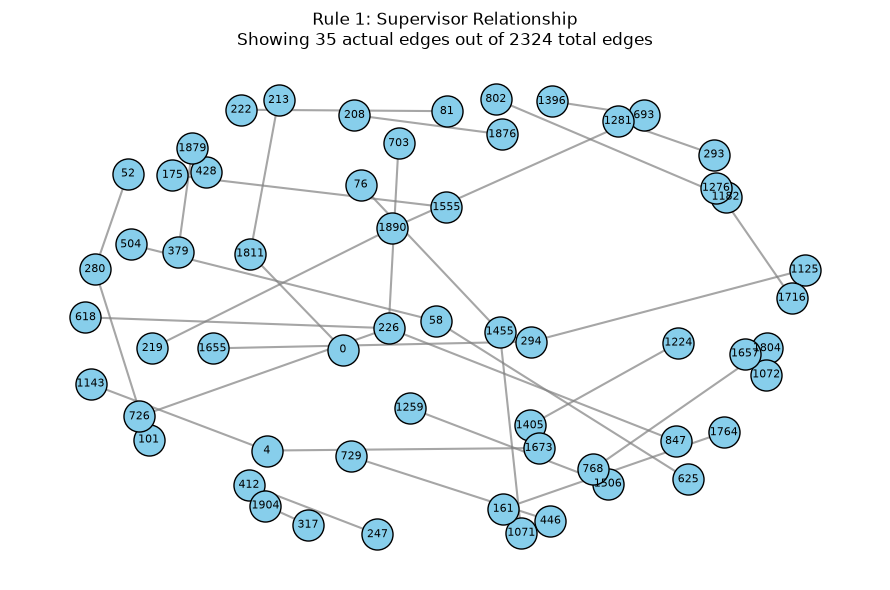


Rule 2: Common Supervisor
Total edges generated: 37879


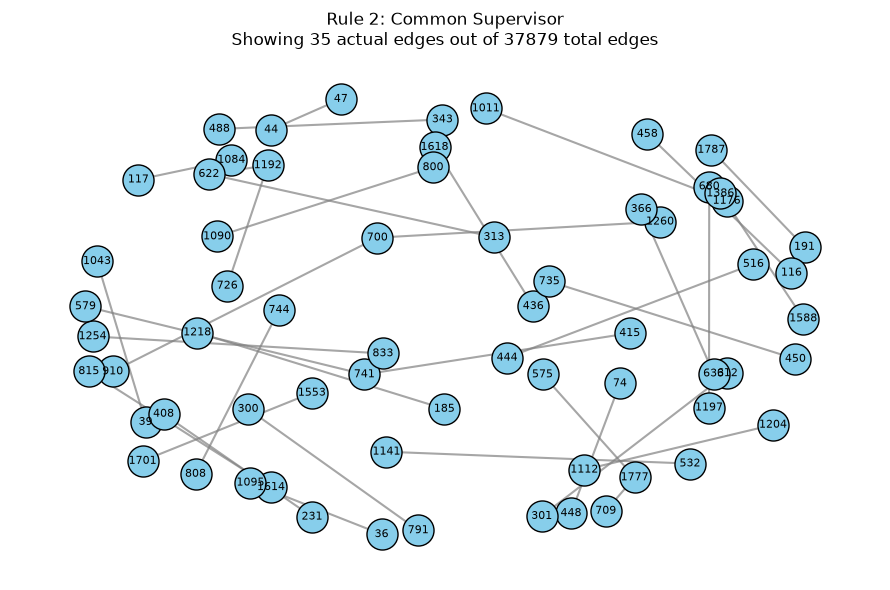


Rule 3: Same User
Total edges generated: 12853


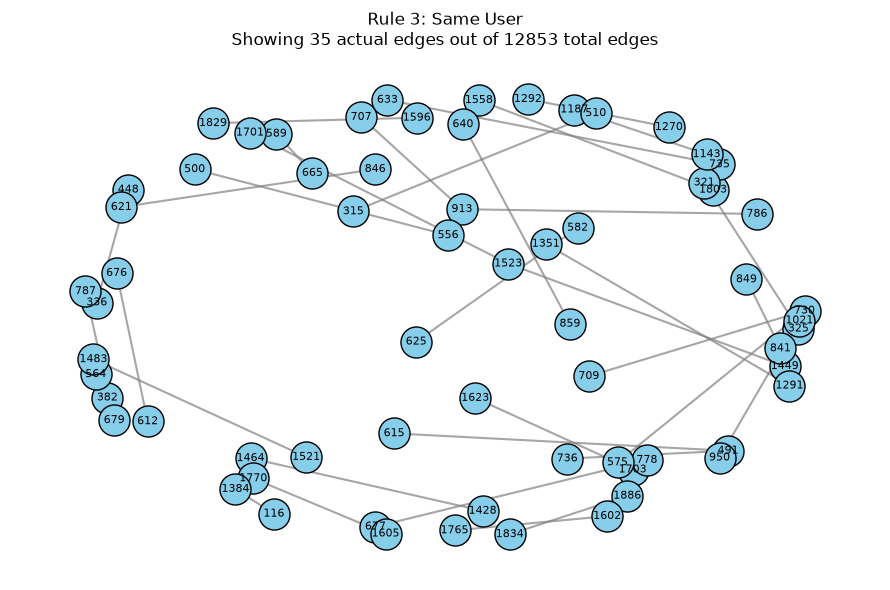


========== PAPER RULE EDGE COUNTS ==========
                      Rule  Total Edges
       Rule 1 - Supervisor         2324
Rule 2 - Common Supervisor        37879
        Rule 3 - Same User        12853


In [39]:

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from itertools import islice

# ==========================================
# 1. BASIC GRAPH PROPERTIES
# ==========================================

print("========== GRAPH PROPERTIES ==========")
print("Number of Nodes:", G_paper.number_of_nodes())
print("Number of Edges:", G_paper.number_of_edges())
print("Is Directed:", nx.is_directed(G_paper))
print("Graph Density:", round(nx.density(G_paper), 5))
print("Average Degree:", round(sum(dict(G_paper.degree()).values()) /
                                G_paper.number_of_nodes(), 2))
print("Connected Components:", nx.number_connected_components(G_paper))

# ==========================================
# 2. PREPARE THE THREE RULE EDGE SETS
# ==========================================

rule_edges = {
    "Rule 1: Supervisor Relationship": set(supervisor_edges),
    "Rule 2: Common Supervisor": set(common_supervisor_edges),
    "Rule 3: Same User": set(same_user_edges)
}

# ==========================================
# 3. FUNCTION TO VISUALIZE EACH RULE
# ==========================================

def visualize_rule(rule_name, edge_set, max_edges=35):

    print(f"\n{rule_name}")
    print("Total edges generated:", len(edge_set))

    if not edge_set:
        print("No edges available for this rule.")
        return

    # Select actual edges from this rule
    selected_edges = list(islice(iter(edge_set), max_edges))

    # Create a representative subgraph
    H = nx.Graph()
    H.add_edges_from(selected_edges)

    # Layout
    plt.figure(figsize=(9, 6))
    pos = nx.spring_layout(H, seed=42, k=0.8)

    # Draw actual connections
    nx.draw_networkx_edges(
        H, pos,
        edge_color="gray",
        width=1.5,
        alpha=0.7
    )

    nx.draw_networkx_nodes(
        H, pos,
        node_color="skyblue",
        node_size=500,
        edgecolors="black"
    )

    nx.draw_networkx_labels(
        H, pos,
        font_size=8
    )

    plt.title(
        f"{rule_name}\n"
        f"Showing {H.number_of_edges()} actual edges "
        f"out of {len(edge_set)} total edges",
        fontsize=12
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ==========================================
# 4. VISUALIZE ALL THREE PAPER RULES
# ==========================================

for rule_name, edge_set in rule_edges.items():
    visualize_rule(rule_name, edge_set)


# ==========================================
# 5. EDGE COUNTS FOR THE THREE RULES
# ==========================================

rule_summary = pd.DataFrame({
    "Rule": [
        "Rule 1 - Supervisor",
        "Rule 2 - Common Supervisor",
        "Rule 3 - Same User"
    ],
    "Total Edges": [
        len(supervisor_edges),
        len(common_supervisor_edges),
        len(same_user_edges)
    ]
})

print("\n========== PAPER RULE EDGE COUNTS ==========")
print(rule_summary.to_string(index=False))


========== FINAL ORGANIZATIONAL GRAPH ==========
Number of Nodes: 1908
Number of Edges: 53056
Directed: False
Density: 0.02916
Average Degree: 55.61
Connected Components: 22

========== RULE-WISE EDGE COUNTS ==========
Rule 1 - Supervisor: 2324
Rule 2 - Common Supervisor: 37879
Rule 3 - Same User: 12853
Combined Unique Edges: 53056


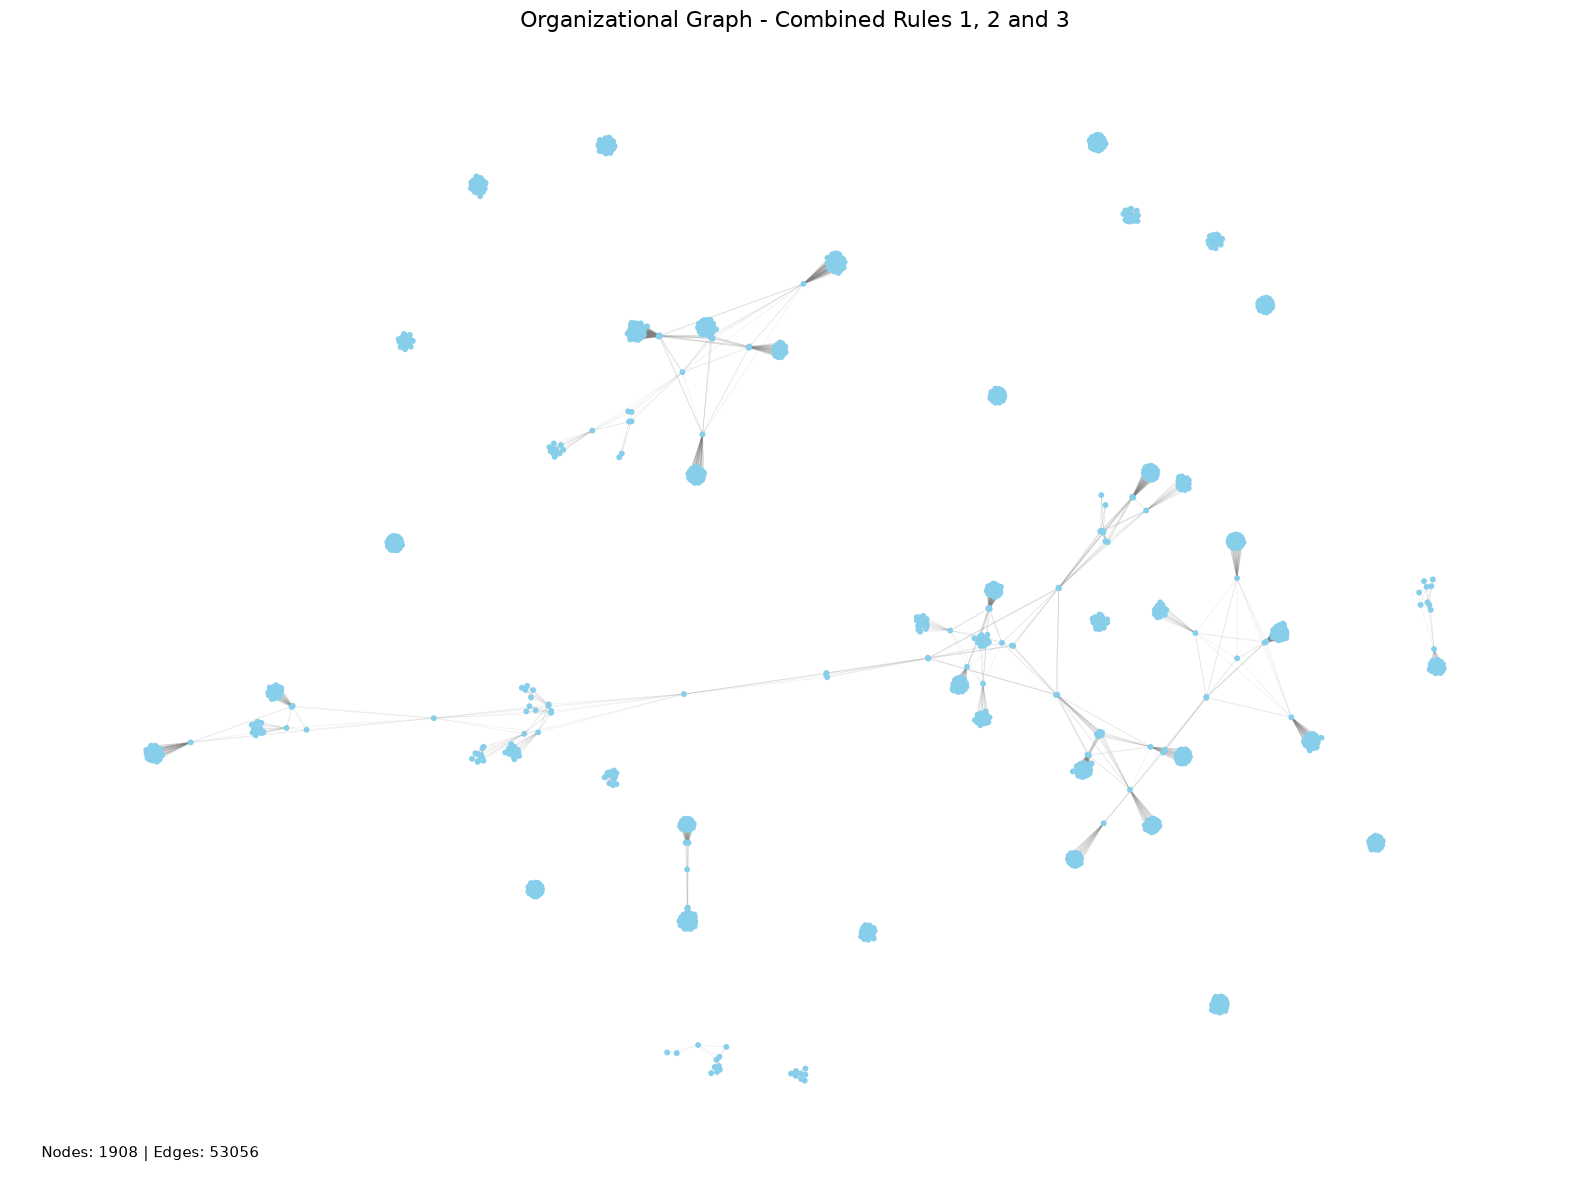

In [40]:

import networkx as nx
import matplotlib.pyplot as plt

# =====================================
# 1. COMBINE ALL THREE PAPER RULES
# =====================================

all_edges = (
    set(supervisor_edges)
    | set(common_supervisor_edges)
    | set(same_user_edges)
)

# Build final organizational graph
G_final = nx.Graph()

# Add all 1908 User-Day Sample nodes
G_final.add_nodes_from(nodes["node_id"])

# Add combined edges from all three rules
G_final.add_edges_from(all_edges)

# =====================================
# 2. BASIC GRAPH PROPERTIES
# =====================================

print("========== FINAL ORGANIZATIONAL GRAPH ==========")
print("Number of Nodes:", G_final.number_of_nodes())
print("Number of Edges:", G_final.number_of_edges())
print("Directed:", nx.is_directed(G_final))
print("Density:", round(nx.density(G_final), 5))
print("Average Degree:", round(
    sum(dict(G_final.degree()).values()) /
    G_final.number_of_nodes(), 2
))
print("Connected Components:",
      nx.number_connected_components(G_final))

print("\n========== RULE-WISE EDGE COUNTS ==========")
print("Rule 1 - Supervisor:", len(supervisor_edges))
print("Rule 2 - Common Supervisor:", len(common_supervisor_edges))
print("Rule 3 - Same User:", len(same_user_edges))
print("Combined Unique Edges:", len(all_edges))

# =====================================
# 3. SINGLE COMBINED GRAPH VISUALIZATION
# =====================================

plt.figure(figsize=(16, 12))

pos = nx.spring_layout(
    G_final,
    seed=42,
    k=0.15,
    iterations=100
)

nx.draw_networkx_edges(
    G_final,
    pos,
    edge_color="gray",
    alpha=0.18,
    width=0.35
)

nx.draw_networkx_nodes(
    G_final,
    pos,
    node_color="skyblue",
    node_size=18,
    edgecolors="none"
)

plt.title(
    "Organizational Graph - Combined Rules 1, 2 and 3",
    fontsize=16
)

plt.text(
    0.02, 0.02,
    f"Nodes: {G_final.number_of_nodes()} | "
    f"Edges: {G_final.number_of_edges()}",
    transform=plt.gca().transAxes,
    fontsize=11
)

plt.axis("off")
plt.tight_layout()
plt.savefig("final_organizational_graph.png",
            dpi=300, bbox_inches="tight")
plt.show()


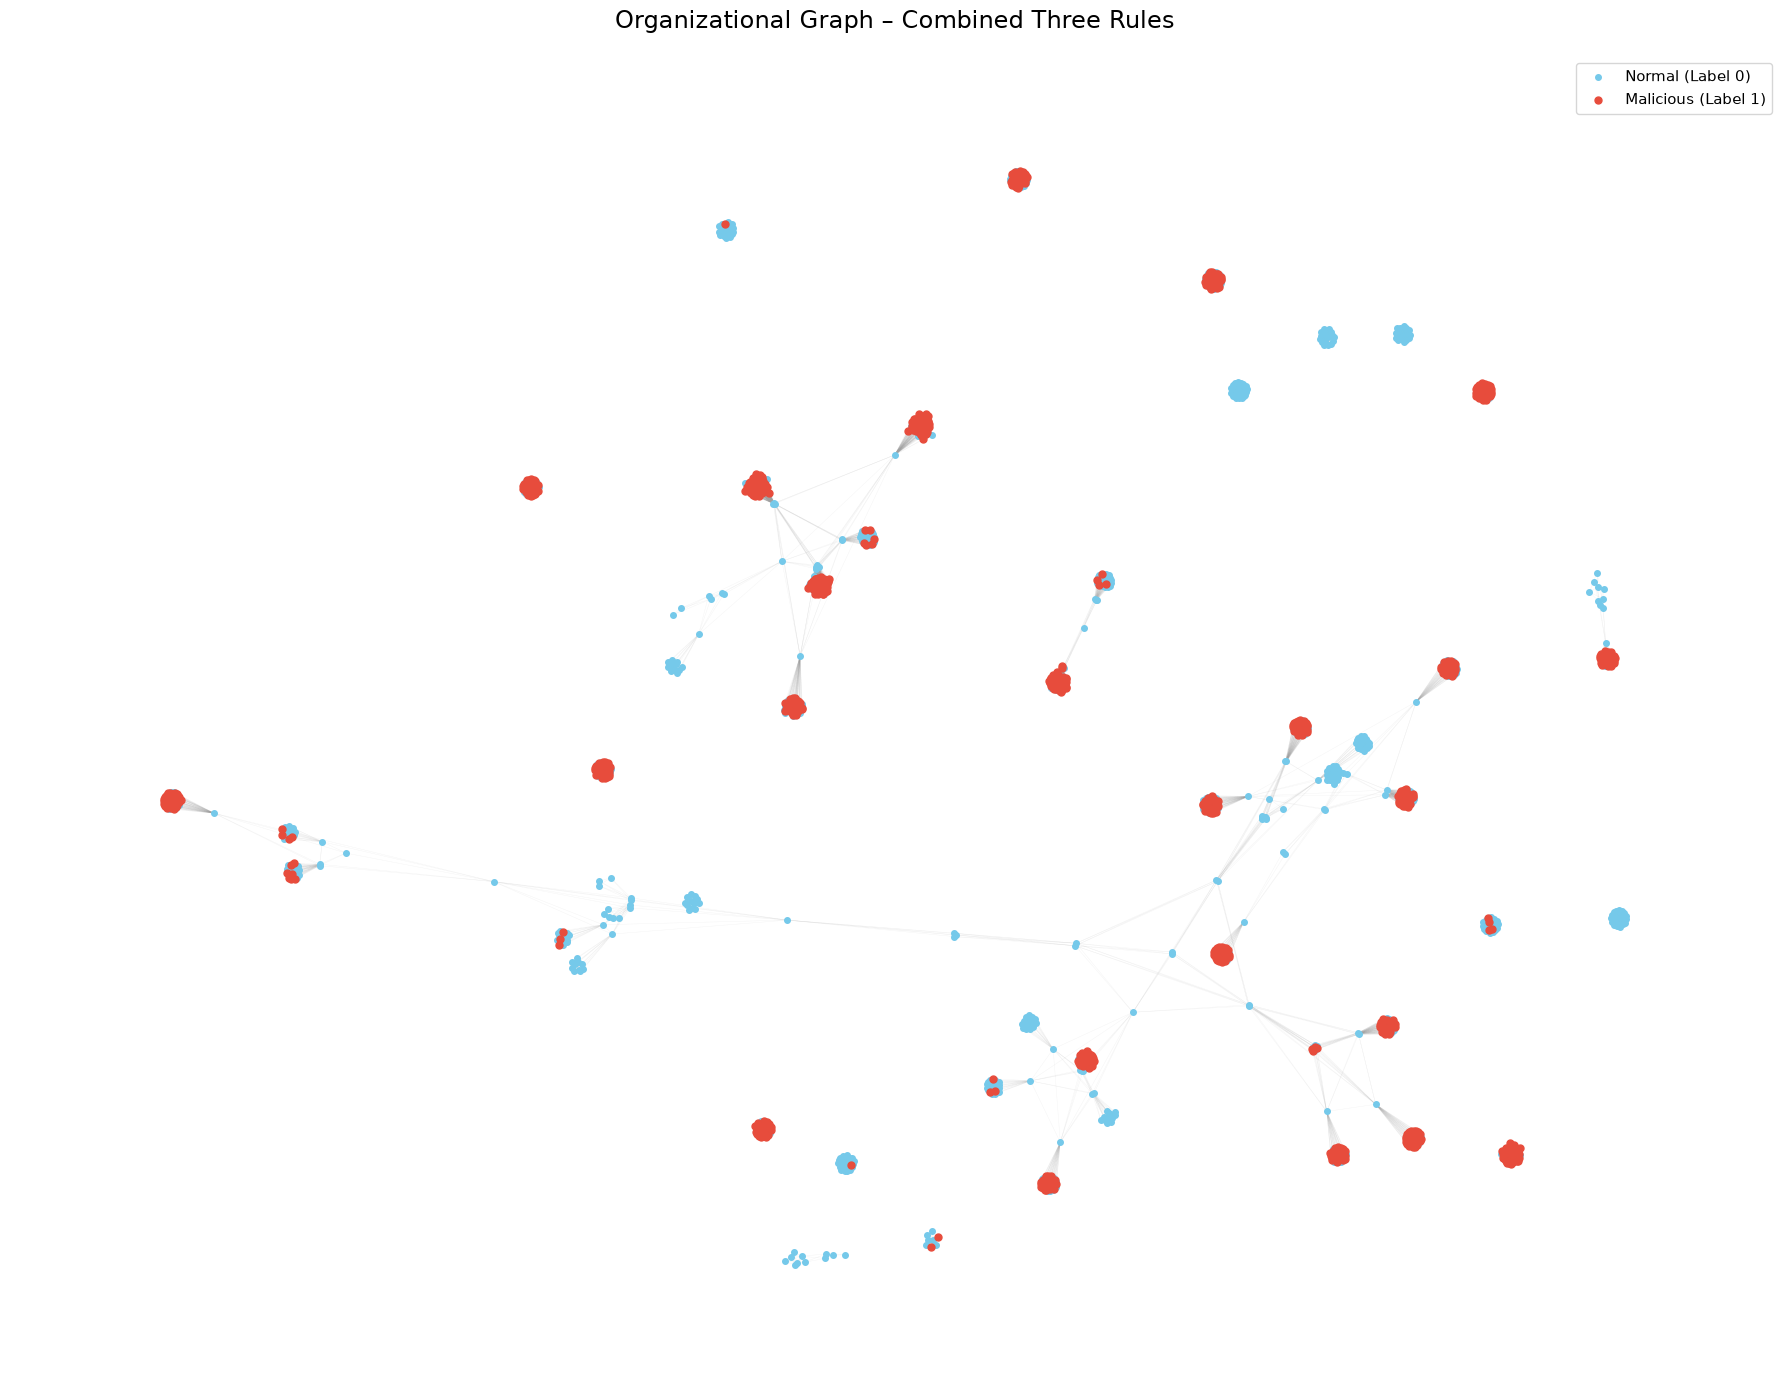

In [41]:

import networkx as nx
import matplotlib.pyplot as plt

# Use the combined graph already created
G_final = nx.Graph()
G_final.add_nodes_from(nodes["node_id"])
G_final.add_edges_from(all_edges)

# Assign labels to nodes
label_map = nodes.set_index("node_id")["label"].to_dict()

normal_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 0
]

malicious_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 1
]

# Layout
pos = nx.spring_layout(
    G_final,
    seed=42,
    k=0.35,
    iterations=150
)

# Plot
fig, ax = plt.subplots(figsize=(18, 14))

# Edges
nx.draw_networkx_edges(
    G_final, pos,
    ax=ax,
    edge_color="#A0A0A0",
    alpha=0.12,
    width=0.3
)

# Normal nodes
nx.draw_networkx_nodes(
    G_final, pos,
    nodelist=normal_nodes,
    node_color="#75C9EA",
    node_size=16,
    label="Normal (Label 0)",
    ax=ax
)

# Malicious nodes
nx.draw_networkx_nodes(
    G_final, pos,
    nodelist=malicious_nodes,
    node_color="#E74C3C",
    node_size=25,
    label="Malicious (Label 1)",
    ax=ax
)

ax.set_title(
    "Organizational Graph – Combined Three Rules",
    fontsize=17,
    pad=20
)

ax.legend(loc="upper right", fontsize=11)
ax.axis("off")

plt.tight_layout()
plt.savefig(
    "organizational_graph_final.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


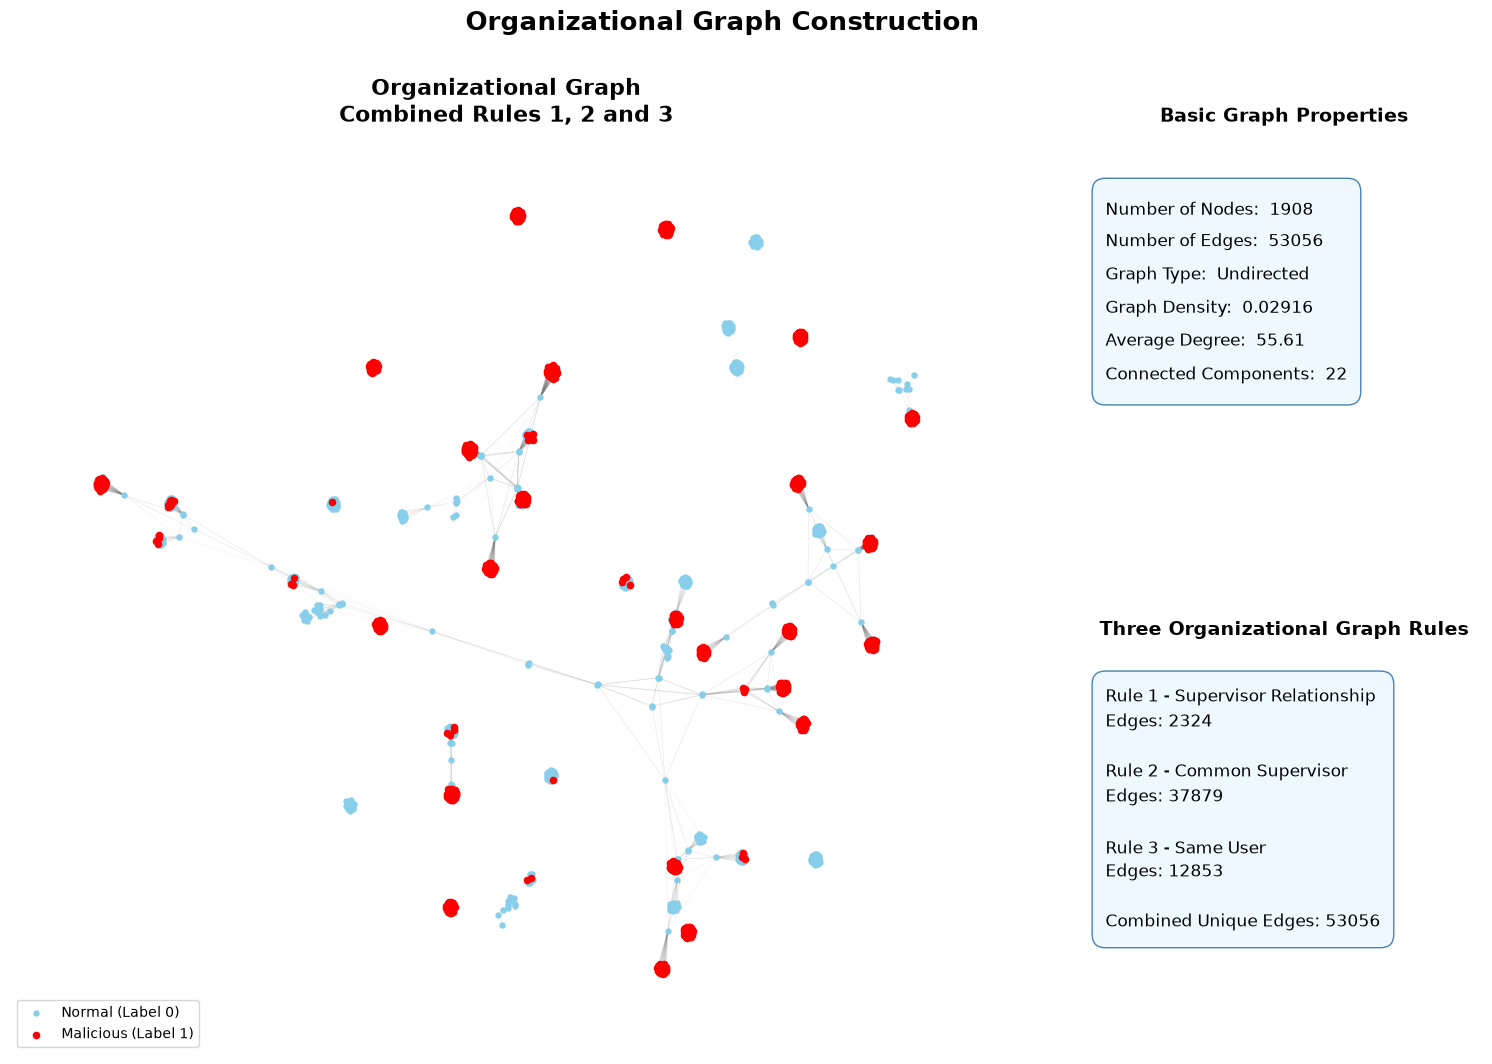


========== BASIC GRAPH PROPERTIES ==========
Number of Nodes: 1908
Number of Edges: 53056
Graph Type: Undirected
Graph Density: 0.02916
Average Degree: 55.61
Connected Components: 22

========== RULE EDGE COUNTS ==========
Rule 1: 2324
Rule 2: 37879
Rule 3: 12853
Combined Unique Edges: 53056


In [42]:

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# =========================================
# 1. COMBINE THREE RULES
# =========================================

all_edges = (
    set(supervisor_edges)
    | set(common_supervisor_edges)
    | set(same_user_edges)
)

G_final = nx.Graph()
G_final.add_nodes_from(nodes["node_id"])
G_final.add_edges_from(all_edges)

# =========================================
# 2. GRAPH PROPERTIES
# =========================================

num_nodes = G_final.number_of_nodes()
num_edges = G_final.number_of_edges()
density = nx.density(G_final)
avg_degree = sum(dict(G_final.degree()).values()) / num_nodes
components = nx.number_connected_components(G_final)

properties = [
    ("Number of Nodes", num_nodes),
    ("Number of Edges", num_edges),
    ("Graph Type", "Undirected"),
    ("Graph Density", round(density, 5)),
    ("Average Degree", round(avg_degree, 2)),
    ("Connected Components", components)
]

# =========================================
# 3. NODE CLASSIFICATION
# =========================================

label_map = nodes.set_index("node_id")["label"].to_dict()

normal_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 0
]

malicious_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 1
]

# =========================================
# 4. CREATE ONE FIGURE
# =========================================

fig = plt.figure(figsize=(19, 12))

gs = GridSpec(
    2, 2,
    figure=fig,
    width_ratios=[2.5, 1],
    height_ratios=[1, 1],
    wspace=0.12,
    hspace=0.25
)

ax_graph = fig.add_subplot(gs[:, 0])
ax_properties = fig.add_subplot(gs[0, 1])
ax_rules = fig.add_subplot(gs[1, 1])

# =========================================
# 5. GRAPH LAYOUT
# =========================================

pos = nx.spring_layout(
    G_final,
    seed=42,
    k=0.05,
    iterations=200
)

# Draw edges
nx.draw_networkx_edges(
    G_final,
    pos,
    ax=ax_graph,
    edge_color="gray",
    alpha=0.12,
    width=0.35
)

# Draw normal nodes
nx.draw_networkx_nodes(
    G_final,
    pos,
    nodelist=normal_nodes,
    node_color="skyblue",
    node_size=13,
    label="Normal (Label 0)",
    ax=ax_graph
)

# Draw malicious nodes
nx.draw_networkx_nodes(
    G_final,
    pos,
    nodelist=malicious_nodes,
    node_color="red",
    node_size=20,
    label="Malicious (Label 1)",
    ax=ax_graph
)

ax_graph.set_title(
    "Organizational Graph\nCombined Rules 1, 2 and 3",
    fontsize=16,
    fontweight="bold"
)

ax_graph.legend(loc="lower left")
ax_graph.axis("off")

# =========================================
# 6. DISPLAY BASIC PROPERTIES
# =========================================

ax_properties.axis("off")
ax_properties.set_title(
    "Basic Graph Properties",
    fontsize=14,
    fontweight="bold"
)

property_text = "\n".join(
    [f"{name}:  {value}" for name, value in properties]
)

ax_properties.text(
    0.05, 0.85,
    property_text,
    fontsize=12,
    verticalalignment="top",
    linespacing=2.0,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="aliceblue",
        edgecolor="steelblue"
    )
)

# =========================================
# 7. RULE-WISE EDGE COUNTS
# =========================================

ax_rules.axis("off")
ax_rules.set_title(
    "Three Organizational Graph Rules",
    fontsize=14,
    fontweight="bold"
)

rule_text = (
    f"Rule 1 - Supervisor Relationship\n"
    f"Edges: {len(supervisor_edges)}\n\n"
    f"Rule 2 - Common Supervisor\n"
    f"Edges: {len(common_supervisor_edges)}\n\n"
    f"Rule 3 - Same User\n"
    f"Edges: {len(same_user_edges)}\n\n"
    f"Combined Unique Edges: {len(all_edges)}"
)

ax_rules.text(
    0.05, 0.9,
    rule_text,
    fontsize=12,
    verticalalignment="top",
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="aliceblue",
        edgecolor="steelblue"
    )
)

# =========================================
# 8. FINAL OUTPUT
# =========================================

fig.suptitle(
    "Organizational Graph Construction",
    fontsize=19,
    fontweight="bold"
)

plt.savefig(
    "organizational_graph_with_properties.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print properties as well
print("\n========== BASIC GRAPH PROPERTIES ==========")
for name, value in properties:
    print(f"{name}: {value}")

print("\n========== RULE EDGE COUNTS ==========")
print("Rule 1:", len(supervisor_edges))
print("Rule 2:", len(common_supervisor_edges))
print("Rule 3:", len(same_user_edges))
print("Combined Unique Edges:", len(all_edges))


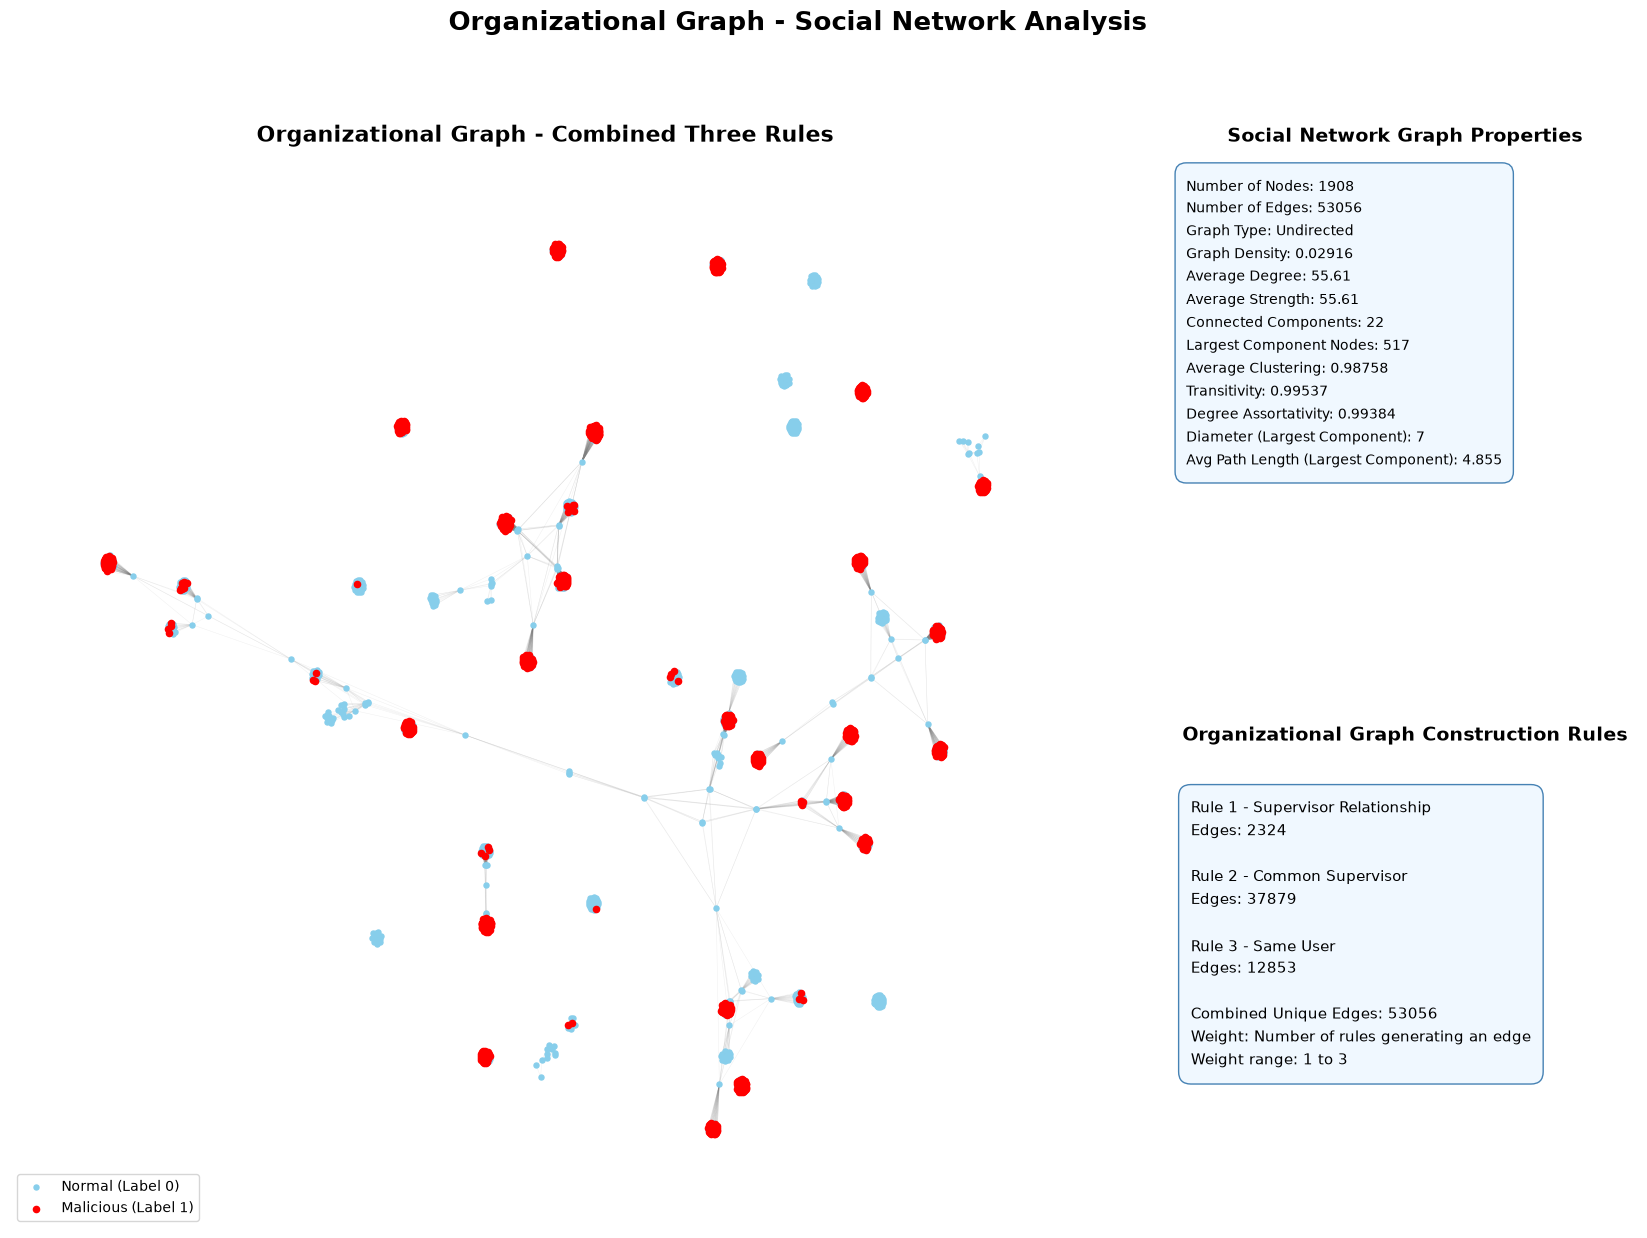


========== TOP 5 BY DEGREE ==========
 node_id user_index                date  label   Degree
     226    SCP0130 2010-05-03 00:00:00      0 0.067646
      33    FEB0306 2010-01-19 00:00:00      0 0.061877
      55    HSP0290 2010-01-28 00:00:00      0 0.061877
      88    ILR0304 2010-02-16 00:00:00      0 0.061877
     156    ICH0294 2010-03-26 00:00:00      0 0.061877

========== TOP 5 BY BETWEENNESS ==========
 node_id user_index                date  label  Betweenness
     826    HCS0003 2010-09-07 00:00:00      0     0.030327
     368    SLB0049 2010-07-01 00:00:00      0     0.028166
    1446    FUM0015 2011-01-14 00:00:00      0     0.024898
     226    SCP0130 2010-05-03 00:00:00      0     0.020907
     871    FAW0032 2010-09-14 00:00:00      0     0.017179

========== TOP 5 BY CLOSENESS ==========
 node_id user_index                date  label  Closeness
     226    SCP0130 2010-05-03 00:00:00      0   0.132881
       4    SBD0913 2010-01-04 00:00:00      0   0.129988
    1

In [43]:

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
from matplotlib.gridspec import GridSpec

# ==================================================
# 1. COMBINE ALL THREE RULES AND CALCULATE EDGE WEIGHTS
# ==================================================

R1 = set(supervisor_edges)
R2 = set(common_supervisor_edges)
R3 = set(same_user_edges)

# Count how many rules generated each unique edge
edge_weights = Counter()

for edge_set in [R1, R2, R3]:
    for u, v in edge_set:
        edge_weights[tuple(sorted((u, v)))] += 1

# Build weighted organizational graph
G_final = nx.Graph()
G_final.add_nodes_from(nodes["node_id"])

for (u, v), weight in edge_weights.items():
    G_final.add_edge(u, v, weight=weight)

# ==================================================
# 2. BASIC GRAPH PROPERTIES
# ==================================================

num_nodes = G_final.number_of_nodes()
num_edges = G_final.number_of_edges()

degree_values = dict(G_final.degree())
strength_values = dict(G_final.degree(weight="weight"))

density = nx.density(G_final)
avg_degree = sum(degree_values.values()) / num_nodes
avg_strength = sum(strength_values.values()) / num_nodes

components = list(nx.connected_components(G_final))
num_components = len(components)

avg_clustering = nx.average_clustering(G_final)
transitivity = nx.transitivity(G_final)

try:
    degree_assortativity = nx.degree_assortativity_coefficient(G_final)
except Exception:
    degree_assortativity = float("nan")

# Largest connected component
largest_component_nodes = max(components, key=len)
G_largest = G_final.subgraph(largest_component_nodes).copy()

largest_component_size = G_largest.number_of_nodes()

if largest_component_size > 1:
    diameter = nx.diameter(G_largest)
    avg_shortest_path = nx.average_shortest_path_length(G_largest)
else:
    diameter = 0
    avg_shortest_path = 0

# ==================================================
# 3. CENTRALITY MEASURES
# ==================================================

degree_centrality = nx.degree_centrality(G_final)

betweenness_centrality = nx.betweenness_centrality(
    G_final,
    normalized=True
)

closeness_centrality = nx.closeness_centrality(G_final)

pagerank = nx.pagerank(
    G_final,
    alpha=0.85,
    weight=None
)

try:
    eigenvector_centrality = nx.eigenvector_centrality(
        G_final,
        max_iter=2000,
        weight=None
    )
except nx.PowerIterationFailedConvergence:
    eigenvector_centrality = {n: float("nan") for n in G_final.nodes()}

# ==================================================
# 4. CREATE NODE-WISE CENTRALITY TABLE
# ==================================================

centrality_df = pd.DataFrame({
    "node_id": list(G_final.nodes()),
    "Degree": [degree_centrality[n] for n in G_final.nodes()],
    "Betweenness": [betweenness_centrality[n] for n in G_final.nodes()],
    "Closeness": [closeness_centrality[n] for n in G_final.nodes()],
    "Eigenvector": [eigenvector_centrality[n] for n in G_final.nodes()],
    "PageRank": [pagerank[n] for n in G_final.nodes()],
    "Degree_Count": [degree_values[n] for n in G_final.nodes()],
    "Weighted_Degree": [strength_values[n] for n in G_final.nodes()]
})

# Add employee/sample information
centrality_df = centrality_df.merge(
    nodes,
    left_on="node_id",
    right_on="node_id",
    how="left"
)

centrality_df.to_csv("organizational_graph_centrality.csv", index=False)

# ==================================================
# 5. COLLECT GRAPH PROPERTIES
# ==================================================

properties = [
    ("Number of Nodes", num_nodes),
    ("Number of Edges", num_edges),
    ("Graph Type", "Undirected"),
    ("Graph Density", round(density, 5)),
    ("Average Degree", round(avg_degree, 2)),
    ("Average Strength", round(avg_strength, 2)),
    ("Connected Components", num_components),
    ("Largest Component Nodes", largest_component_size),
    ("Average Clustering", round(avg_clustering, 5)),
    ("Transitivity", round(transitivity, 5)),
    ("Degree Assortativity", round(degree_assortativity, 5)),
    ("Diameter (Largest Component)", diameter),
    ("Avg Path Length (Largest Component)", round(avg_shortest_path, 3))
]

# ==================================================
# 6. CREATE DASHBOARD
# ==================================================

fig = plt.figure(figsize=(21, 14))

gs = GridSpec(
    2, 2,
    figure=fig,
    width_ratios=[2.3, 1],
    height_ratios=[1, 1],
    wspace=0.12,
    hspace=0.25
)

ax_graph = fig.add_subplot(gs[:, 0])
ax_properties = fig.add_subplot(gs[0, 1])
ax_rules = fig.add_subplot(gs[1, 1])

# ==================================================
# 7. VISUALIZE COMBINED ORGANIZATIONAL GRAPH
# ==================================================

pos = nx.spring_layout(
    G_final,
    seed=42,
    k=0.05,
    iterations=200
)

label_map = nodes.set_index("node_id")["label"].to_dict()

normal_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 0
]

malicious_nodes = [
    n for n in G_final.nodes()
    if label_map.get(n) == 1
]

# Draw edges
nx.draw_networkx_edges(
    G_final,
    pos,
    ax=ax_graph,
    edge_color="gray",
    alpha=0.12,
    width=0.35
)

# Normal nodes
nx.draw_networkx_nodes(
    G_final,
    pos,
    nodelist=normal_nodes,
    node_color="skyblue",
    node_size=13,
    label="Normal (Label 0)",
    ax=ax_graph
)

# Malicious nodes
nx.draw_networkx_nodes(
    G_final,
    pos,
    nodelist=malicious_nodes,
    node_color="red",
    node_size=20,
    label="Malicious (Label 1)",
    ax=ax_graph
)

ax_graph.set_title(
    "Organizational Graph - Combined Three Rules",
    fontsize=16,
    fontweight="bold"
)

ax_graph.legend(loc="lower left")
ax_graph.axis("off")

# ==================================================
# 8. DISPLAY GRAPH PROPERTIES
# ==================================================

ax_properties.axis("off")

ax_properties.set_title(
    "Social Network Graph Properties",
    fontsize=14,
    fontweight="bold"
)

property_text = "\n".join(
    [f"{name}: {value}" for name, value in properties]
)

ax_properties.text(
    0.03, 0.95,
    property_text,
    fontsize=10,
    verticalalignment="top",
    linespacing=1.65,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="aliceblue",
        edgecolor="steelblue"
    )
)

# ==================================================
# 9. RULE-WISE EDGE COUNTS AND WEIGHT INFORMATION
# ==================================================

ax_rules.axis("off")

ax_rules.set_title(
    "Organizational Graph Construction Rules",
    fontsize=14,
    fontweight="bold"
)

rule_text = (
    f"Rule 1 - Supervisor Relationship\n"
    f"Edges: {len(R1)}\n\n"
    f"Rule 2 - Common Supervisor\n"
    f"Edges: {len(R2)}\n\n"
    f"Rule 3 - Same User\n"
    f"Edges: {len(R3)}\n\n"
    f"Combined Unique Edges: {num_edges}\n"
    f"Weight: Number of rules generating an edge\n"
    f"Weight range: 1 to 3"
)

ax_rules.text(
    0.04, 0.9,
    rule_text,
    fontsize=11,
    verticalalignment="top",
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="aliceblue",
        edgecolor="steelblue"
    )
)

# ==================================================
# 10. FINAL DASHBOARD
# ==================================================

fig.suptitle(
    "Organizational Graph - Social Network Analysis",
    fontsize=19,
    fontweight="bold"
)

plt.savefig(
    "organizational_graph_SNA_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==================================================
# 11. PRINT TOP CENTRALITY NODES
# ==================================================

centrality_metrics = [
    "Degree",
    "Betweenness",
    "Closeness",
    "Eigenvector",
    "PageRank"
]

for metric in centrality_metrics:
    print(f"\n========== TOP 5 BY {metric.upper()} ==========")
    print(
        centrality_df.nlargest(5, metric)[
            ["node_id", "user_index", "date", "label", metric]
        ].to_string(index=False)
    )

# ==================================================
# 12. PRINT ALL GRAPH PROPERTIES
# ==================================================

print("\n========== SOCIAL NETWORK GRAPH PROPERTIES ==========")

for name, value in properties:
    print(f"{name}: {value}")

print("\n========== WEIGHT INFORMATION ==========")
print("Weight 1 edges:", sum(w == 1 for w in edge_weights.values()))
print("Weight 2 edges:", sum(w == 2 for w in edge_weights.values()))
print("Weight 3 edges:", sum(w == 3 for w in edge_weights.values()))

print("\nCentrality CSV saved successfully.")
